In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pymongo import MongoClient

# 1. Conexión a MongoDB y extracción de datos crudos
cliente = MongoClient("mongodb://localhost:27017/")
coleccion = cliente["taller3_db"]["raw_data"]
datos_crudos = list(coleccion.find())

# 2. Selección de 6 variables relevantes (El taller exige mínimo 5)
datos_procesados = []
for d in datos_crudos:
    # Aplanamos el JSON para sacar el diámetro máximo en kilómetros
    diametro_km = d.get('estimated_diameter', {}).get('kilometers', {}).get('estimated_diameter_max', None)
    
    datos_procesados.append({
        "id": d.get("id"),
        "nombre": d.get("name"),
        "magnitud_absoluta": d.get("absolute_magnitude_h"),
        "diametro_km_max": diametro_km,
        "es_peligroso": d.get("is_potentially_hazardous_asteroid"),
        "es_centinela": d.get("is_sentry_object")
    })

# 3. Creación del DataFrame de Pandas
df = pd.DataFrame(datos_procesados)

# 4. Inspección Básica (Requisito estricto de la Fase 3)
print("--- Primeras 5 filas del DataFrame ---")
display(df.head())

print("\n--- Información de los tipos de datos ---")
df.info()

print("\n--- Verificación de Datos Nulos ---")
print(df.isnull().sum())

--- Primeras 5 filas del DataFrame ---


,id,nombre,magnitud_absoluta,diametro_km_max,es_peligroso,es_centinela
0,2001620,1620 Geographos (1951 RA),15.27,5.248558,True,False
1,2001863,1863 Antinous (1948 EA),15.32,5.129086,False,False
2,2001915,1915 Quetzalcoatl (1953 EA),18.38,1.253257,False,False
3,2001917,1917 Cuyo (1968 AA),14.38,7.907514,False,False
4,2002063,2063 Bacchus (1977 HB),17.21,2.148028,False,False



--- Información de los tipos de datos ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 300 non-null    object 
 1   nombre             300 non-null    object 
 2   magnitud_absoluta  300 non-null    float64
 3   diametro_km_max    300 non-null    float64
 4   es_peligroso       300 non-null    bool   
 5   es_centinela       300 non-null    bool   
dtypes: bool(2), float64(2), object(2)
memory usage: 10.1+ KB

--- Verificación de Datos Nulos ---
id                   0
nombre               0
magnitud_absoluta    0
diametro_km_max      0
es_peligroso         0
es_centinela         0
dtype: int64


In [2]:
# 5 Insights Numéricos (Requisito de la Fase 3)
print("--- 5 Insights Numéricos Relevantes ---")

# 1. Total de registros analizados
total_asteroides = len(df)
print(f"1. Total de asteroides en la muestra: {total_asteroides}")

# 2. Promedio del diámetro máximo
promedio_diametro = df['diametro_km_max'].mean()
print(f"2. Diámetro máximo promedio: {promedio_diametro:.3f} km")

# 3. Conteo de asteroides peligrosos
peligrosos = df['es_peligroso'].sum()
print(f"3. Asteroides clasificados como peligrosos: {peligrosos}")

# 4. Porcentaje de peligrosidad
porcentaje_peligrosos = (peligrosos / total_asteroides) * 100
print(f"4. Porcentaje de asteroides peligrosos: {porcentaje_peligrosos:.1f}%")

# 5. Asteroide más grande de la muestra
asteroide_mas_grande = df.loc[df['diametro_km_max'].idxmax()]
print(f"5. Asteroide más grande: '{asteroide_mas_grande['nombre']}' ({asteroide_mas_grande['diametro_km_max']:.2f} km)")

--- 5 Insights Numéricos Relevantes ---
1. Total de asteroides en la muestra: 300
2. Diámetro máximo promedio: 3.837 km
3. Asteroides clasificados como peligrosos: 74
4. Porcentaje de asteroides peligrosos: 24.7%
5. Asteroide más grande: '1036 Ganymed (A924 UB)' (87.10 km)


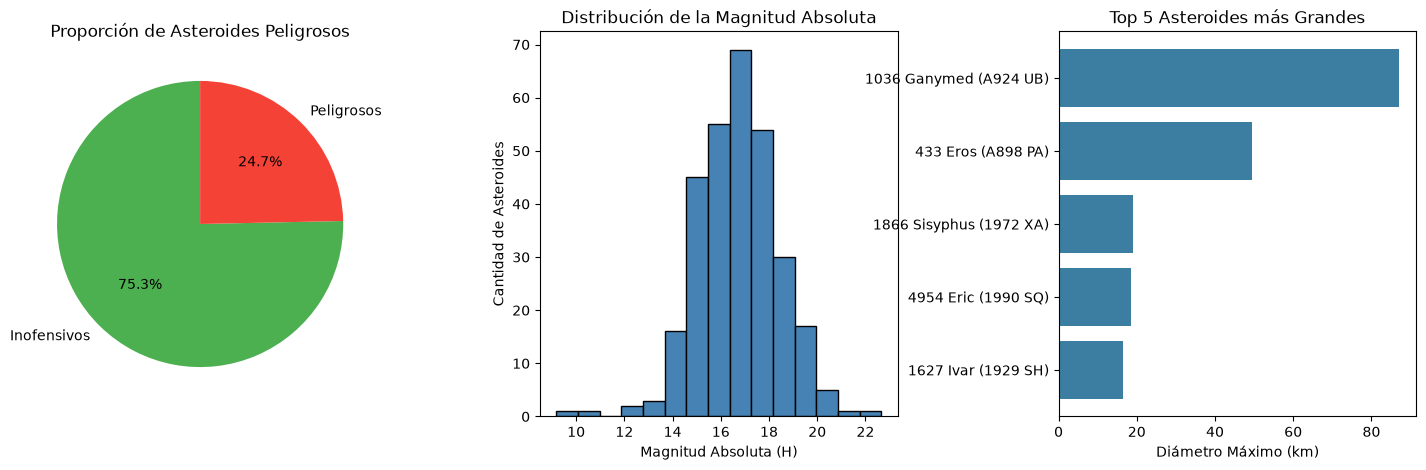

In [ ]:
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(19, 5.8), facecolor='#FAFAFA')
plt.subplots_adjust(wspace=0.42, top=0.80)
fig.suptitle(
    "Análisis Exploratorio de Asteroides Cercanos a la Tierra (NASA NeoWs)",
    fontsize=16,
    fontweight='bold',
    color='#1F2937'
)

conteo_peligro = df['es_peligroso'].value_counts()
colores_dona = ['#10B981', '#EF4444']
wedges, texts, autotexts = axes[0].pie(
    conteo_peligro,
    labels=['Inofensivos', 'Peligrosos'],
    autopct='%1.1f%%',
    startangle=90,
    colors=colores_dona,
    explode=(0, 0.06),
    pctdistance=0.76,
    wedgeprops={'width': 0.42, 'edgecolor': '#FAFAFA', 'linewidth': 2.5},
    textprops={'fontsize': 11, 'color': '#374151', 'fontweight': 'bold'}
)
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(10)

axes[0].text(
    0, 0, f"{len(df)}\nAsteroides",
    ha='center', va='center',
    fontsize=12, fontweight='bold', color='#1F2937'
)
axes[0].set_title("Proporción de Peligrosidad", fontsize=13, fontweight='bold', pad=14, color='#111827')

axes[1].set_facecolor('#FFFFFF')
axes[1].hist(df['magnitud_absoluta'], bins=15, color='#3B82F6', edgecolor='#1D4ED8', alpha=0.85)
media_mag = df['magnitud_absoluta'].mean()
axes[1].axvline(media_mag, color='#EF4444', linestyle='--', linewidth=2, label=f'Promedio: {media_mag:.2f}')
axes[1].set_title("Distribución de Magnitud Absoluta", fontsize=13, fontweight='bold', pad=14, color='#111827')
axes[1].set_xlabel("Magnitud Absoluta (H)", fontsize=11, color='#374151')
axes[1].set_ylabel("Cantidad de Asteroides", fontsize=11, color='#374151')
axes[1].grid(axis='y', linestyle='--', alpha=0.4)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].legend(frameon=True, facecolor='#FAFAFA', fontsize=10)

axes[2].set_facecolor('#FFFFFF')
top_5 = df.nlargest(5, 'diametro_km_max').sort_values('diametro_km_max', ascending=True)
colores_barras = plt.cm.Blues(np.linspace(0.45, 0.9, len(top_5)))
barras = axes[2].barh(top_5['nombre'], top_5['diametro_km_max'], color=colores_barras, height=0.62)
axes[2].set_title("Top 5 Asteroides más Grandes", fontsize=13, fontweight='bold', pad=14, color='#111827')
axes[2].set_xlabel("Diámetro Máximo Estimado (km)", fontsize=11, color='#374151')
axes[2].set_xlim(0, top_5['diametro_km_max'].max() * 1.18)
axes[2].grid(axis='x', linestyle='--', alpha=0.4)
axes[2].spines['top'].set_visible(False)
axes[2].spines['right'].set_visible(False)
axes[2].tick_params(axis='y', labelsize=10)

for barra in barras:
    ancho = barra.get_width()
    axes[2].text(
        ancho + 1.5,
        barra.get_y() + barra.get_height() / 2,
        f"{ancho:.1f} km",
        va='center',
        ha='left',
        fontsize=10,
        fontweight='bold',
        color='#1F2937'
    )

plt.show()